<a href="https://colab.research.google.com/github/igupansini/utfpr-AI/blob/main/POSIA05-Redes_Neurais_Artificiais/Tarefa_MLPRegressor_TDNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Exercício MLPRegressor - TDNN (Time Delay Neural Network) - Previsão da Variação de Valor de uma Mercadoria

Rede Perceptron Multicamadas (MLP) com topologia Time Delay (TDNN), utilizada para prever o comportamento futuro do preço de uma mercadoria comercializada no mercado financeiro de ações. A cada instante t, a rede recebe os p valores anteriores da série {x(t-1), x(t-2), ..., x(t-p)} e estima o valor seguinte f(t). A rede é constituída de duas camadas neurais (uma camada oculta com N1 neurônios e uma camada de saída com um neurônio), conforme a topologia apresentada no enunciado.

Topologias candidatas:
- Rede 1: 5 entradas (p = 5) com N1 = 15
- Rede 2: 10 entradas (p = 10) com N1 = 25
- Rede 3: 15 entradas (p = 15) com N1 = 50

Dataset: 120 amostras (variacaoValores.csv). As amostras t = 1 a 100 são o histórico de treinamento do Anexo e as amostras t = 101 a 120 são os valores desejados da tabela de validação do Item 4.

In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn import metrics
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Carregamento e Organização Inicial do Dataset

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/UTFPR_IA/variacaoValores.csv")

df_treino = df[df['Amostra'] <= 100] # Histórico de treinamento do Anexo (t = 1 a 100)
df_teste = df[df['Amostra'] > 100] # Valores desejados da tabela de validação (t = 101 a 120)

print('Amostras de treinamento:', df_treino.shape)
print('Amostras de validação:', df_teste.shape)
df.head()

Amostras de treinamento: (100, 2)
Amostras de validação: (20, 2)


,Amostra,f(t)
0,1,0.1701
1,2,0.1023
2,3,0.4405
3,4,0.3609
4,5,0.7192


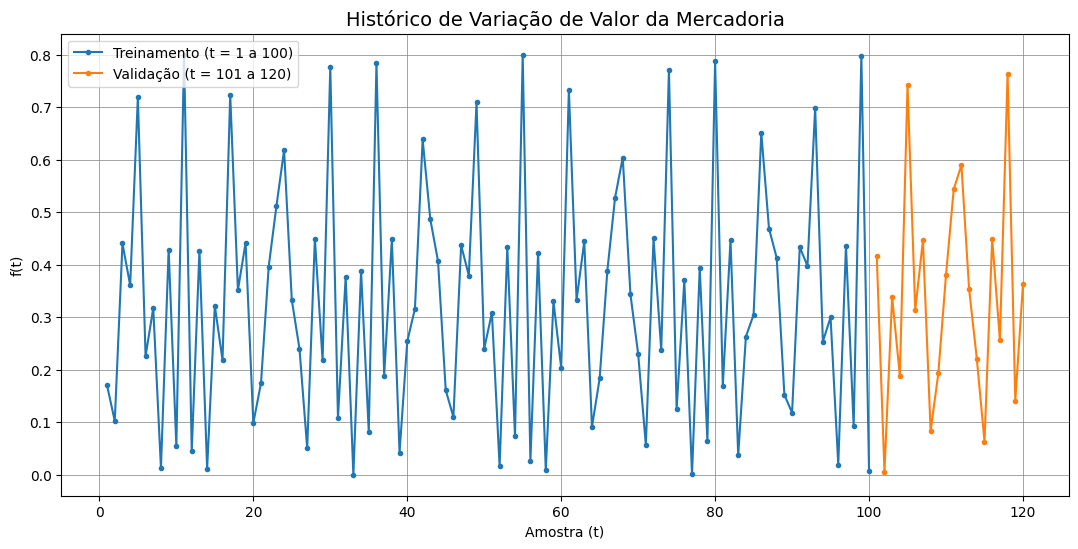

In [ ]:
plt.figure(figsize=(13,6))
plt.plot(df_treino['Amostra'], df_treino['f(t)'], marker='o', markersize=3, label='Treinamento (t = 1 a 100)')
plt.plot(df_teste['Amostra'], df_teste['f(t)'], marker='o', markersize=3, label='Validação (t = 101 a 120)')
plt.title("Histórico de Variação de Valor da Mercadoria", fontsize=14)
plt.xlabel('Amostra (t)')
plt.ylabel('f(t)')
plt.legend()
plt.grid(which='major', linestyle='-', linewidth='0.5', color='gray')
plt.show()

Pré-Processamento dos Dados

Não é aplicado StandardScaler() nem MinMaxScaler(), pois os valores de f(t) já se encontram no intervalo [0, 1] (ver describe() abaixo). Assim, as métricas de erro ficam na mesma escala dos valores desejados da tabela do enunciado.

Também não é utilizado train_test_split(). Como se trata de uma série temporal, a separação segue a ordem do tempo definida no enunciado: o treinamento usa somente o histórico até t = 100 e a validação usa as amostras t = 101 a 120.

As amostras da TDNN são montadas com uma janela deslizante: para uma rede com p entradas, cada amostra tem como entradas {x(t-1), ..., x(t-p)} e como saída desejada f(t). Por isso cada rede fica com 100 - p amostras de treinamento (as p primeiras não têm histórico suficiente) e sempre 20 amostras de validação. Nas amostras de validação, as entradas são os valores reais anteriores da série (previsão um passo à frente), de modo que a amostra t = 101 usa como entradas os últimos p valores do treinamento.

In [ ]:
dados = df['f(t)'].values

def gerar_amostras(p):
    linhas = []
    for t in range(p, len(dados)): # A janela começa em p para que toda amostra tenha os p valores anteriores
        linhas.append([df['Amostra'].iloc[t]] + [dados[t - k] for k in range(1, p + 1)] + [dados[t]])
    colunas = ['Amostra'] + ['x(t-' + str(k) + ')' for k in range(1, p + 1)] + ['f(t)']
    return pd.DataFrame(linhas, columns=colunas)

redes = {'Rede 1': {'p': 5, 'N1': 15},
         'Rede 2': {'p': 10, 'N1': 25},
         'Rede 3': {'p': 15, 'N1': 50}}

amostras = {}
for rede in redes:
    df_amostras = gerar_amostras(redes[rede]['p'])
    df_amostras_treino = df_amostras[df_amostras['Amostra'] <= 100]
    df_amostras_teste = df_amostras[df_amostras['Amostra'] > 100]
    amostras[rede] = {'trainX': df_amostras_treino.drop(columns=['Amostra', 'f(t)']),
                      'trainY': df_amostras_treino['f(t)'],
                      'testX': df_amostras_teste.drop(columns=['Amostra', 'f(t)']),
                      'testY': df_amostras_teste['f(t)']}
    print(rede, '- p =', redes[rede]['p'], '- N1 =', redes[rede]['N1'],
          '- Amostras de treinamento:', len(df_amostras_treino), '- Amostras de validação:', len(df_amostras_teste))

df.describe()

Rede 1 - p = 5 - N1 = 15 - Amostras de treinamento: 95 - Amostras de validação: 20
Rede 2 - p = 10 - N1 = 25 - Amostras de treinamento: 90 - Amostras de validação: 20
Rede 3 - p = 15 - N1 = 50 - Amostras de treinamento: 85 - Amostras de validação: 20


,Amostra,f(t)
count,120.000000,120.000000
mean,60.500000,0.330615
std,34.785054,0.224801
min,1.000000,0.000100
25%,30.750000,0.149500
50%,60.500000,0.331550
75%,90.250000,0.445025
max,120.000000,0.800000


In [ ]:
df_exemplo = gerar_amostras(5) # Exemplo das amostras montadas para a Rede 1 (p = 5)
pd.concat([df_exemplo.head(3), df_exemplo[df_exemplo['Amostra'].between(100, 102)]])

,Amostra,x(t-1),x(t-2),x(t-3),x(t-4),x(t-5),f(t)
0,6,0.7192,0.3609,0.4405,0.1023,0.1701,0.2258
1,7,0.2258,0.7192,0.3609,0.4405,0.1023,0.3175
2,8,0.3175,0.2258,0.7192,0.3609,0.4405,0.0127
94,100,0.7984,0.0924,0.4366,0.0195,0.2998,0.0077
95,101,0.0077,0.7984,0.0924,0.4366,0.0195,0.4173
96,102,0.4173,0.0077,0.7984,0.0924,0.4366,0.0062


Item 1 - Treinamento da Rede 1 com o Solver SGD

Um treinamento da Rede 1 (p = 5 e N1 = 15) com as configurações do enunciado: activation='relu', solver='sgd', max_iter=5000, tol=0.000001, momentum=0.9, early_stopping=True, epsilon=1e-06, learning_rate_init=0.001 e learning_rate='constant'. Os demais hiperparâmetros ficam no padrão do MLPRegressor.

Com early_stopping=True, o MLPRegressor separa 10% das amostras de treinamento (validation_fraction padrão) para uma validação interna e encerra o treinamento quando essa validação deixa de melhorar por 10 épocas seguidas (n_iter_no_change padrão), mantendo os pesos da melhor época. Como o batch_size padrão é min(200, amostras) e há menos de 200 amostras, cada época corresponde a um único ajuste dos pesos com todas as amostras. O parâmetro epsilon só é utilizado pelo adam, então não tem efeito com o sgd.

Observação: como os pesos iniciais e a separação da validação interna são sorteados a cada execução (nenhum random_state é fixado), os valores de perda e de épocas mudam a cada nova execução.

In [ ]:
trainX = amostras['Rede 1']['trainX']
trainY = amostras['Rede 1']['trainY']
testX = amostras['Rede 1']['testX']
testY = amostras['Rede 1']['testY']

mlp_sgd = MLPRegressor(hidden_layer_sizes=(15), activation='relu', solver='sgd', max_iter=5000, tol=0.000001,
                       momentum=0.9, early_stopping=True, epsilon=1e-06,
                       learning_rate_init=0.001, learning_rate='constant')

# Execução do treinamento da RNA
mlp_sgd.fit(trainX, trainY)

print('Perda Final:', mlp_sgd.loss_)
print('Épocas:', mlp_sgd.n_iter_)

Perda Final: 0.00457159483327824
Épocas: 5000


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (5000) reached and the optimization hasn't converged yet.
  warnings.warn(


Item 2 - Treinamento da Rede 1 com o Solver Adam

Mesmo treinamento do Item 1, alterando somente o solver para 'adam'. No MLPRegressor do sklearn, os parâmetros momentum e learning_rate são exclusivos do sgd e são ignorados pelo adam, que ajusta o passo de cada peso com as próprias estimativas de momento (beta_1 e beta_2, no padrão). Eles foram mantidos na chamada apenas para que a única diferença entre os dois treinamentos seja o solver. Já o epsilon=1e-06 passa a ter efeito, pois é usado pelo adam.

In [ ]:
mlp_adam = MLPRegressor(hidden_layer_sizes=(15), activation='relu', solver='adam', max_iter=5000, tol=0.000001,
                        momentum=0.9, early_stopping=True, epsilon=1e-06,
                        learning_rate_init=0.001, learning_rate='constant')

# Execução do treinamento da RNA
mlp_adam.fit(trainX, trainY)

print('Perda Final:', mlp_adam.loss_)
print('Épocas:', mlp_adam.n_iter_)

Perda Final: 0.0005632318178053953
Épocas: 1579


Comparação entre SGD e Adam

Os dois treinamentos da Rede 1 são comparados pela perda final, pelo número de épocas e pelas métricas nas 20 amostras de validação (t = 101 a 120). O solver escolhido para o Item 3 é o que obteve a menor perda final.

In [ ]:
resultados_solver = []
for solver, modelo in [('sgd', mlp_sgd), ('adam', mlp_adam)]:
    y_pred = modelo.predict(testX)
    resultados_solver.append({'Solver': solver,
                              'Perda (loss)': modelo.loss_,
                              'Épocas': modelo.n_iter_,
                              'MAE': metrics.mean_absolute_error(testY, y_pred),
                              'MSE': metrics.mean_squared_error(testY, y_pred),
                              'R2': metrics.r2_score(testY, y_pred)})

tabela_solver = pd.DataFrame(resultados_solver)

solver_escolhido = tabela_solver.sort_values('Perda (loss)').iloc[0]['Solver'] # Solver com a menor perda final, utilizado no Item 3
print('Solver escolhido para o Item 3:', solver_escolhido)
tabela_solver

Solver escolhido para o Item 3: adam


,Solver,Perda (loss),Épocas,MAE,MSE,R2
0,sgd,0.004572,5000,0.071448,0.008440,0.798250
1,adam,0.000563,1579,0.031102,0.001525,0.963553


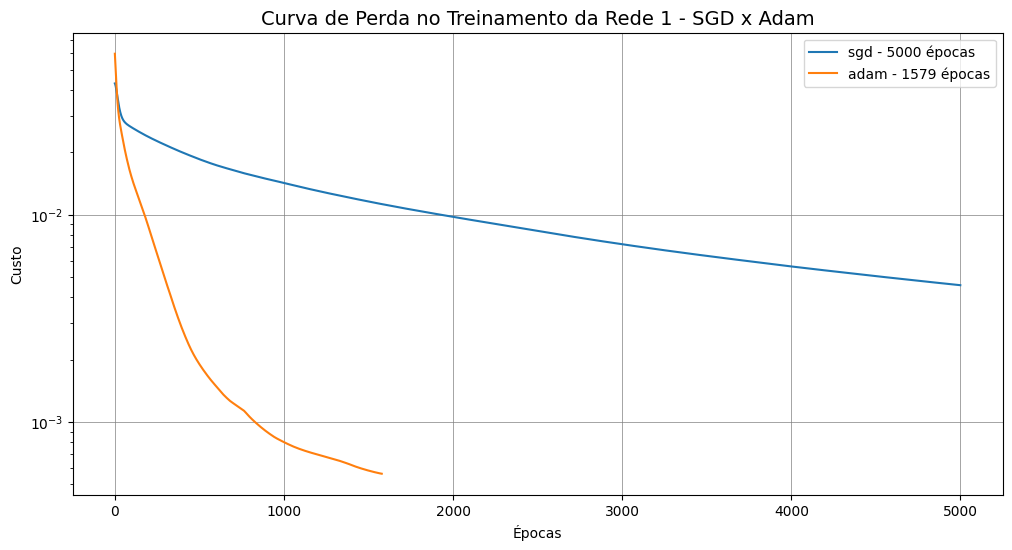

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(mlp_sgd.loss_curve_, label='sgd - ' + str(mlp_sgd.n_iter_) + ' épocas')
plt.plot(mlp_adam.loss_curve_, label='adam - ' + str(mlp_adam.n_iter_) + ' épocas')
plt.title("Curva de Perda no Treinamento da Rede 1 - SGD x Adam", fontsize=14)
plt.xlabel('Épocas')
plt.ylabel('Custo')
plt.yscale('log')
plt.legend()
plt.grid(which='major', linestyle='-', linewidth='0.5', color='gray')
plt.show()

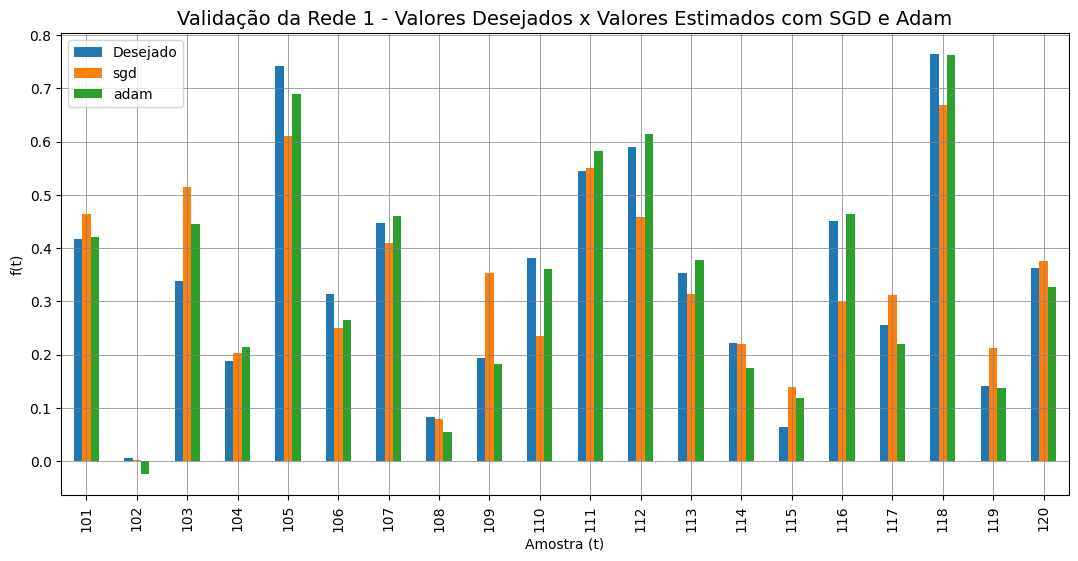

In [ ]:
df_temp = pd.DataFrame({'Desejado': testY.values, 'sgd': mlp_sgd.predict(testX), 'adam': mlp_adam.predict(testX)},
                       index=df_teste['Amostra'])
df_temp.plot(kind='bar', figsize=(13,6))
plt.title("Validação da Rede 1 - Valores Desejados x Valores Estimados com SGD e Adam", fontsize=14)
plt.xlabel('Amostra (t)')
plt.ylabel('f(t)')
plt.grid(which='major', linestyle='-', linewidth='0.5', color='gray')
plt.grid(which='minor', linestyle=':', linewidth='0.5', color='blue')
plt.show() # Apresenta o gráfico comparando o desejado e o estimado pelos dois solvers

Comentário do Item 2

Com o adam, a Rede 1 chegou a uma perda 8.1 vezes menor que a do sgd (0.000563 contra 0.004572) e parou pelo early stopping em 1579 épocas. Já o sgd esgotou as 5000 épocas (ConvergenceWarning) com a perda ainda caindo. Na validação, o MAE caiu de 0.0714 para 0.0311 e o R2 subiu de 0.798 para 0.964.

O sgd avança devagar nesta configuração: cada época faz um único ajuste dos pesos, proporcional ao gradiente multiplicado pela taxa de 0.001. O adam divide o gradiente de cada peso pela média móvel do seu tamanho, então os pesos continuam avançando mesmo quando o gradiente fica pequeno. Como alertado no enunciado, momentum e learning_rate não têm efeito no adam.

Por ter a menor perda final, o adam é o solver utilizado no Item 3.

Item 3 - Três Treinamentos para cada Topologia

Cada uma das três redes é treinada 3 vezes com o solver escolhido no Item 2 e as mesmas configurações do Item 1. Nenhum random_state é fixado, então as matrizes de pesos sinápticos são inicializadas com valores aleatórios diferentes em cada treinamento.

In [ ]:
resultados = []
modelos = {}

for rede in redes:
    trainX = amostras[rede]['trainX']
    trainY = amostras[rede]['trainY']
    for treinamento in range(1, 4):
        mlp_reg = MLPRegressor(hidden_layer_sizes=(redes[rede]['N1']), activation='relu', solver=solver_escolhido,
                               max_iter=5000, tol=0.000001, momentum=0.9, early_stopping=True, epsilon=1e-06,
                               learning_rate_init=0.001, learning_rate='constant')

        # Execução do treinamento da RNA
        mlp_reg.fit(trainX, trainY)

        modelos[rede + ' (T' + str(treinamento) + ')'] = mlp_reg
        resultados.append({'Rede': rede,
                           'Treinamento': 'T' + str(treinamento),
                           'Perda (loss)': mlp_reg.loss_,
                           'Épocas': mlp_reg.n_iter_})

        print(rede, '- T' + str(treinamento), '- Perda Final:', round(mlp_reg.loss_, 8), '- Épocas:', mlp_reg.n_iter_)

Rede 1 - T1 - Perda Final: 0.03897981 - Épocas: 12
Rede 1 - T2 - Perda Final: 0.00189861 - Épocas: 404
Rede 1 - T3 - Perda Final: 0.0015807 - Épocas: 846
Rede 2 - T1 - Perda Final: 0.00042399 - Épocas: 1940
Rede 2 - T2 - Perda Final: 0.00011644 - Épocas: 1905
Rede 2 - T3 - Perda Final: 0.00080097 - Épocas: 297
Rede 3 - T1 - Perda Final: 0.03473774 - Épocas: 14
Rede 3 - T2 - Perda Final: 2.732e-05 - Épocas: 2278
Rede 3 - T3 - Perda Final: 0.00045457 - Épocas: 517


In [ ]:
tabela = pd.DataFrame(resultados)
tabela_item3 = pd.concat({rede: tabela[tabela['Rede'] == rede].set_index('Treinamento')[['Perda (loss)', 'Épocas']]
                          for rede in redes}, axis=1) # Mesmo formato da tabela do enunciado

print('Solver:', solver_escolhido)
tabela_item3

Solver: adam


Rede 1              Rede 2              Rede 3       
            Perda (loss) Épocas Perda (loss) Épocas Perda (loss) Épocas
Treinamento                                                            
T1              0.038980     12     0.000424   1940     0.034738     14
T2              0.001899    404     0.000116   1905     0.000027   2278
T3              0.001581    846     0.000801    297     0.000455    517

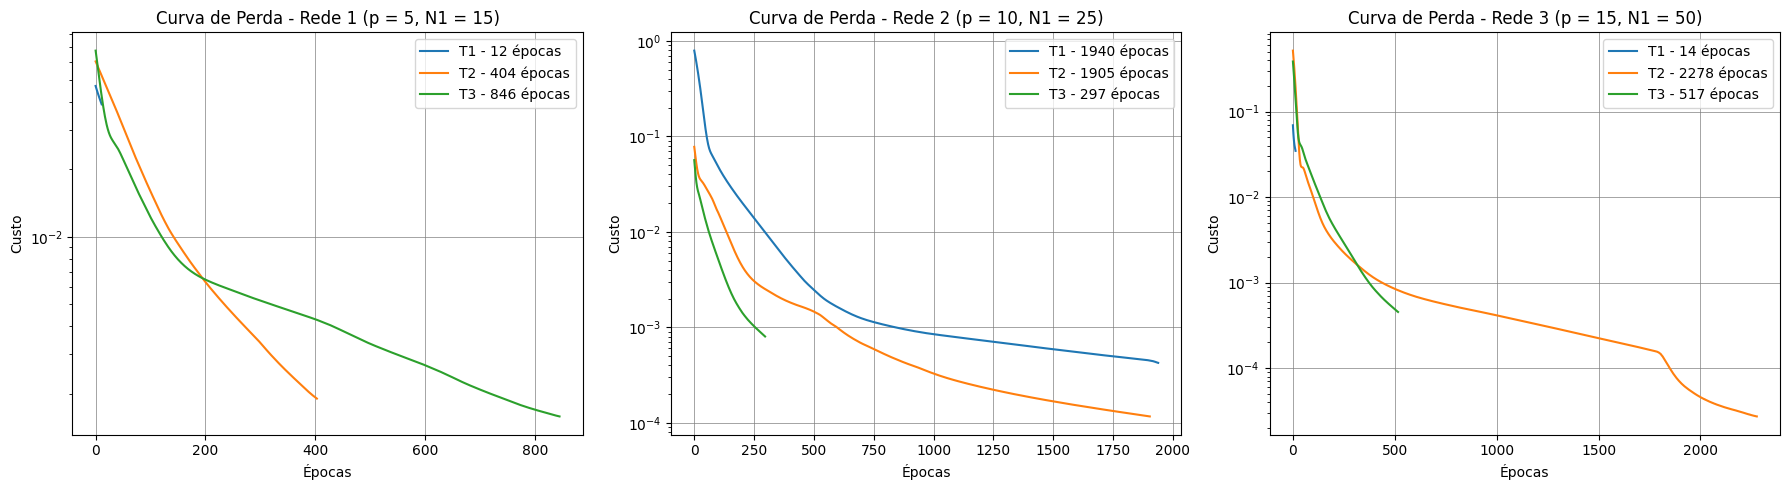

In [ ]:
fig, eixos = plt.subplots(1, 3, figsize=(18,5))
for i, rede in enumerate(redes):
    for treinamento in ['T1', 'T2', 'T3']:
        modelo = modelos[rede + ' (' + treinamento + ')']
        eixos[i].plot(modelo.loss_curve_, label=treinamento + ' - ' + str(modelo.n_iter_) + ' épocas')
    eixos[i].set_title("Curva de Perda - " + rede + " (p = " + str(redes[rede]['p']) + ", N1 = " + str(redes[rede]['N1']) + ")")
    eixos[i].set_xlabel('Épocas')
    eixos[i].set_ylabel('Custo')
    eixos[i].set_yscale('log')
    eixos[i].legend()
    eixos[i].grid(which='major', linestyle='-', linewidth='0.5', color='gray')
plt.tight_layout()
plt.show()

Item 4 - Validação das Redes

Os 9 treinamentos do Item 3 são aplicados às 20 amostras da tabela de validação (t = 101 a 120), que não participaram do treinamento. A primeira tabela traz os valores estimados por cada treinamento, no mesmo formato da tabela do enunciado, e a segunda traz o Erro Absoluto Médio (MAE), o Erro Quadrático Médio (MSE) e o R2 Score de cada treinamento.

In [ ]:
testY = df_teste['f(t)'].values
df_temp = pd.DataFrame({'f(t)': testY}, index=df_teste['Amostra'])
resultados_validacao = []

for rede in redes:
    for treinamento in ['T1', 'T2', 'T3']:
        chave = rede + ' (' + treinamento + ')'
        y_pred = modelos[chave].predict(amostras[rede]['testX'])
        df_temp[chave] = y_pred
        resultados_validacao.append({'Rede': rede,
                                     'Treinamento': treinamento,
                                     'MAE': metrics.mean_absolute_error(testY, y_pred),
                                     'MSE': metrics.mean_squared_error(testY, y_pred),
                                     'R2': metrics.r2_score(testY, y_pred)})

df_temp.round(4)

,f(t),Rede 1 (T1),Rede 1 (T2),Rede 1 (T3),Rede 2 (T1),Rede 2 (T2),Rede 2 (T3),Rede 3 (T1),Rede 3 (T2),Rede 3 (T3)
Amostra,,,,,,,,,,
101,0.4173,0.1926,0.5129,0.4897,0.4228,0.4000,0.4729,0.5138,0.4166,0.3827
102,0.0062,0.5157,-0.0413,-0.0106,-0.0555,-0.0176,-0.0575,0.5760,-0.0030,-0.0286
103,0.3387,0.1311,0.4749,0.3937,0.3462,0.3857,0.3920,0.6058,0.3609,0.3781
104,0.1886,0.4244,0.2616,0.1818,0.1512,0.1530,0.1663,0.3969,0.2022,0.1327
105,0.7418,0.2068,0.7086,0.5765,0.7261,0.7609,0.6810,0.3298,0.7390,0.7466
106,0.3138,0.2514,0.2248,0.2488,0.2480,0.2740,0.2681,0.2436,0.3240,0.2563
107,0.4466,0.1387,0.4409,0.4759,0.4807,0.4338,0.4720,0.4437,0.4400,0.4630
108,0.0835,0.4055,0.0629,0.0223,0.1430,0.0893,0.1392,0.5270,0.0846,0.1067
109,0.1930,0.1501,0.2364,0.1915,0.1779,0.1740,0.1871,0.5795,0.1822,0.2076


In [ ]:
tabela_validacao = pd.DataFrame(resultados_validacao)
tabela_validacao['Ranking'] = tabela_validacao['MSE'].rank(method='min').astype(int) # Classifica os treinamentos do menor para o maior MSE na validação
tabela_validacao

,Rede,Treinamento,MAE,MSE,R2,Ranking
0,Rede 1,T1,0.237940,0.083978,-1.007344,8
1,Rede 1,T2,0.052274,0.004071,0.902685,7
2,Rede 1,T3,0.043330,0.003198,0.923559,6
3,Rede 2,T1,0.024638,0.000999,0.976125,4
4,Rede 2,T2,0.015933,0.000415,0.990070,2
5,Rede 2,T3,0.032355,0.001440,0.965590,5
6,Rede 3,T1,0.249455,0.093705,-1.239852,9
7,Rede 3,T2,0.007536,0.000085,0.997962,1
8,Rede 3,T3,0.021391,0.000758,0.981884,3


In [ ]:
melhor = tabela_validacao.sort_values('Ranking').iloc[0]
print('Melhor treinamento na validação:', melhor['Rede'], '-', melhor['Treinamento'],
      '- MAE:', round(melhor['MAE'], 6), '- MSE:', round(melhor['MSE'], 6), '- R2:', round(melhor['R2'], 6))

tabela_validacao.groupby('Rede')[['MAE', 'MSE', 'R2']].mean() # Média dos 3 treinamentos de cada topologia

Melhor treinamento na validação: Rede 3 - T2 - MAE: 0.007536 - MSE: 8.5e-05 - R2: 0.997962


,MAE,MSE,R2
Rede,,,
Rede 1,0.111182,0.030416,0.272967
Rede 2,0.024309,0.000951,0.977262
Rede 3,0.092794,0.031516,0.246665


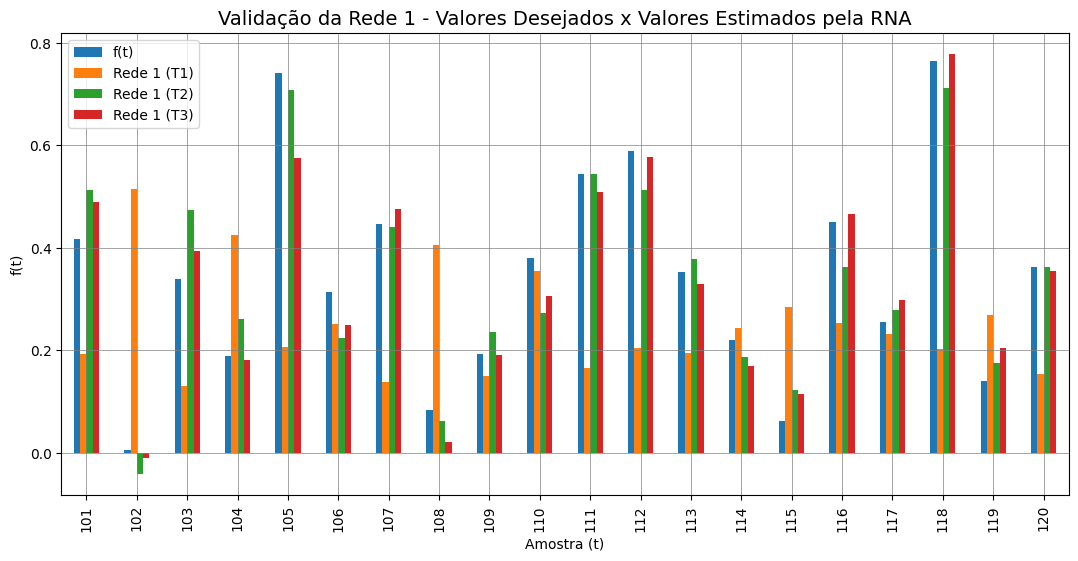

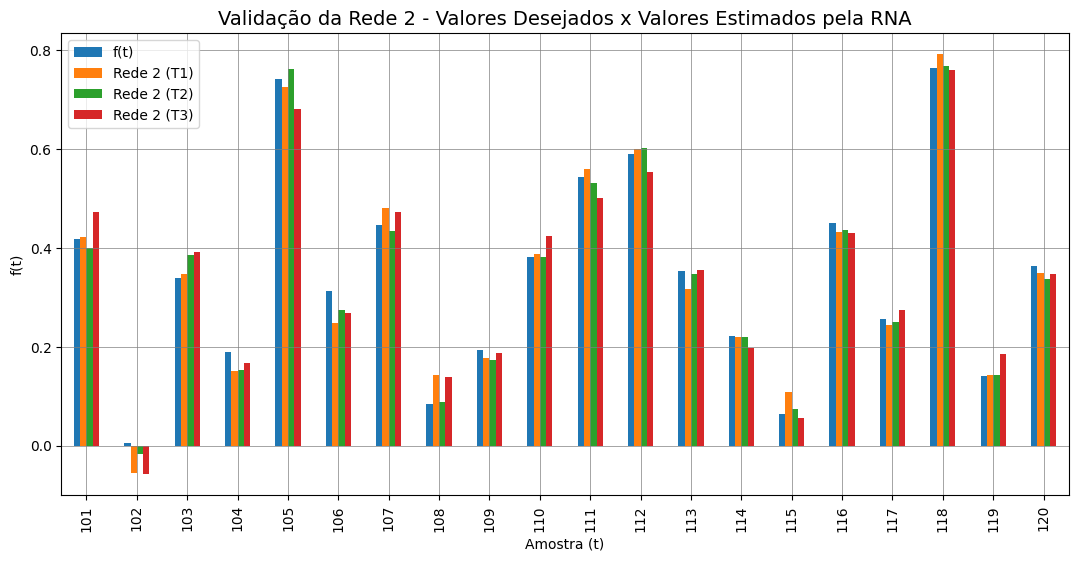

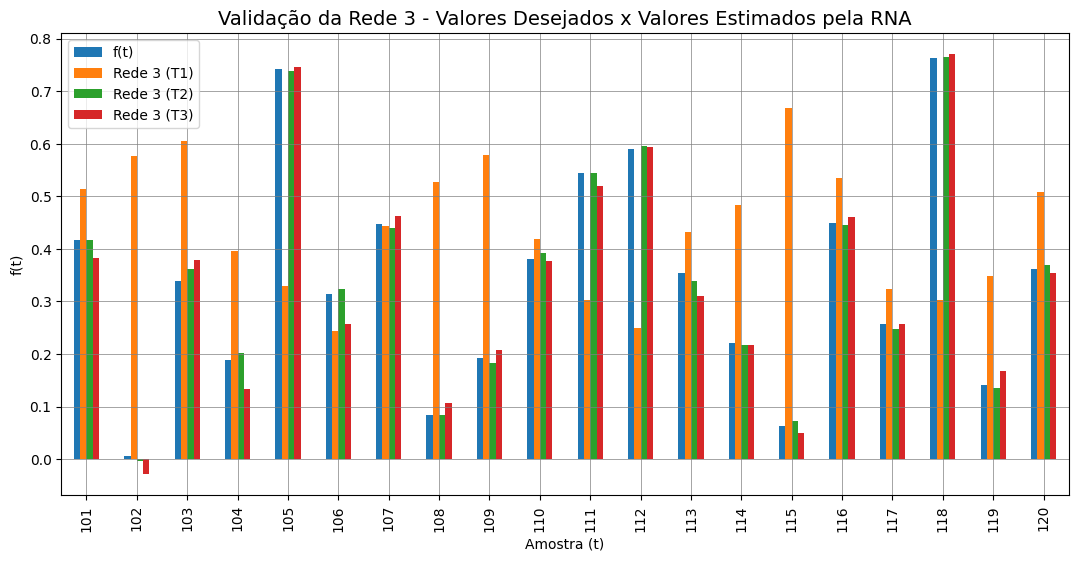

In [ ]:
for rede in redes:
    df_temp[['f(t)', rede + ' (T1)', rede + ' (T2)', rede + ' (T3)']].plot(kind='bar', figsize=(13,6))
    plt.title("Validação da " + rede + " - Valores Desejados x Valores Estimados pela RNA", fontsize=14)
    plt.xlabel('Amostra (t)')
    plt.ylabel('f(t)')
    plt.grid(which='major', linestyle='-', linewidth='0.5', color='gray')
    plt.grid(which='minor', linestyle=':', linewidth='0.5', color='blue')
    plt.show() # Apresenta o gráfico comparando o desejado e o estimado pelos 3 treinamentos da rede

Conclusão

Os números abaixo se referem a esta execução. Como nenhum random_state é fixado, eles mudam a cada nova execução.

- O adam foi claramente superior ao sgd nesta configuração: perda 8 vezes menor, cerca de um terço das épocas e R2 de 0.964 contra 0.798 na validação.
- Com o adam, 7 dos 9 treinamentos convergiram entre 297 e 2278 épocas. A Rede 1 (T1) e a Rede 3 (T1) pararam com 12 e 14 épocas e ficaram com R2 negativo na validação, porque o early stopping decide com apenas 9 ou 10 amostras de validação interna.
- Quando o treinamento converge, mais atrasos e mais neurônios dão previsões melhores: o R2 médio dos treinamentos que convergiram vai de 0.913 (Rede 1) para 0.977 (Rede 2) e 0.990 (Rede 3).
- O melhor treinamento foi o da Rede 3 (T2), com MAE de 0.0075 e R2 de 0.998. A Rede 2 foi a única com os três treinamentos bons (R2 médio de 0.977).
- A ordem dos treinamentos pela perda final é quase a mesma do ranking pelo MSE na validação, então não há sinal de overfitting.
- A Rede 3 é a topologia mais adequada, desde que um treinamento com parada prematura (perda alta e poucas épocas) seja descartado.